# Analisis Kebocoran Margin Promo JSM Alfamart
### Capstone Project Modul 3 — Business & Data Analyst Bootcamp Purwadhika

**Nama:** Raihan Hasbi

---

## Daftar Isi
1. Ringkasan Eksekutif
2. Latar Belakang
3. Problem Statement
4. Tujuan Analisis
5. Stakeholder
6. Data Extract
7. Data Understanding
8. Data Cleaning
9. Analisis
10. Visualisasi
11. Kesimpulan
12. Rekomendasi
13. Keterbatasan Data

## 1. Ringkasan Eksekutif

Promo JSM berhasil menaikkan rata-rata transaksi harian **±18%** pada Jumat–Minggu, tetapi sekitar **separuh subsidi diskonnya (±Rp3,97 M dari Rp7,98 M, Jan 2021–Agu 2025)** jatuh ke pembelian di atas batas wajar rumah tangga.

Seluruh kebocoran itu terjadi di **79 gerai tipe Dekat Pasar/Grosir (7,9% dari 1.003 gerai)**, tempat pembeli sudah berbelanja dalam jumlah besar bahkan tanpa promo. Di gerai perumahan dan perkantoran, promo tidak mengubah jumlah belanja.

Rekomendasi utamanya **bukan menghapus promo**, melainkan menerapkan **batas maksimal 12 pcs per SKU promo per transaksi** saat JSM, diprioritaskan di gerai dekat pasar. Batas ini berpotensi menyelamatkan hingga **±Rp1,2 M per tahun**, dengan hanya **3,4%** transaksi pelanggan rumah tangga yang ikut terkena.

## 2. Latar Belakang

Alfamart mengelola ribuan gerai minimarket. Setiap transaksi kasir tercatat di mesin Point of Sale (POS).

Salah satu program pemasaran rutinnya adalah **Promo JSM (Jumat–Sabtu–Minggu)**, yaitu diskon akhir pekan untuk SKU tertentu. Promo ini dirancang sebagai **loss leader**: margin barang promo dikorbankan supaya pelanggan datang ke gerai dan ikut membeli barang lain.

Skema promo seperti ini punya risiko nyata. Pada awal 2022, saat Harga Eceran Tertinggi minyak goreng ditetapkan (Permendag No. 6/2022), stok di minimarket cepat habis karena sebagian barang **diborong untuk dijual kembali**. Alfamart lalu menerapkan pembatasan pembelian: **maksimal 2 kemasan** ukuran 1 liter per pembeli.

Manajemen kini ingin mengetahui apakah pola serupa terjadi pada Promo JSM.

## 3. Problem Statement

Manajemen Alfamart mengindikasikan adanya **kebocoran margin dari Promo JSM**. Dugaannya, barang promo dibeli dalam jumlah besar oleh segelintir pembeli dengan pola **non-rumah-tangga** (reseller atau pengecer kecil), jauh melampaui kebutuhan konsumen ritel biasa.

Dampaknya:
- Subsidi diskon tidak sampai ke pelanggan yang menjadi target promo.
- Ketersediaan barang promo untuk pelanggan ritel biasa berkurang.

**Periode data:** Januari 2021 – Agustus 2025.

## 4. Tujuan Analisis

1. **Kuantifikasi dampak finansial**: mengestimasi besaran potensi kebocoran margin dari pola pembelian yang mengindikasikan penyalahgunaan Promo JSM.
2. **Desain kebijakan pembatasan**: merumuskan rekomendasi batas kuantitas pembelian per pelanggan untuk SKU promo.

**Pertanyaan bisnis turunan:**
1. Apakah Promo JSM mengubah pola belanja (volume transaksi dan qty per transaksi)?
2. Apakah diskon JSM dinikmati secara merata, atau terkonsentrasi di sebagian kecil transaksi?
3. Berapa rupiah diskon yang jatuh ke pembelian di atas batas wajar rumah tangga?
4. Di mana dan oleh siapa pola borongan terjadi (tipe gerai, member vs non-member)?
5. Berapa batas qty yang paling seimbang antara penghematan dan dampak ke pelanggan biasa?

## 5. Stakeholder

| Stakeholder | Kepentingan terhadap analisis |
|---|---|
| Manajemen / Direksi | Keputusan kebijakan promo dan dampaknya ke margin |
| Tim Marketing & Promo | Desain mekanisme Promo JSM (SKU, diskon, aturan pembelian) |
| Tim Operasional Gerai / Area Manager | Penerapan aturan pembatasan di kasir dan gerai |
| Tim IT / POS | Implementasi pembatasan qty di sistem kasir |

## 6. Data Extract

Data diambil langsung dari **server MySQL Purwadhika** (database `alfamart`) menggunakan library `pymysql`.

**Catatan keamanan:** kredensial server (host, port, user, password) **tidak ditulis di kode**. Semuanya disimpan di **Colab Secrets** (ikon kunci di sidebar Colab) dan dibaca dengan `userdata.get()`, supaya aman saat notebook diunggah ke GitHub.

In [1]:
# !pip install -q pymysql
# import pymysql
# import pandas as pd
# from google.colab import userdata

# def koneksi(db=None):
#     return pymysql.connect(
#         host=userdata.get('DB_HOST'),
#         port=int(userdata.get('DB_PORT')),
#         user=userdata.get('DB_USER'),
#         password=userdata.get('DB_PASSWORD'),
#         database=db,
#         cursorclass=pymysql.cursors.DictCursor,
#     )

# with koneksi() as conn, conn.cursor() as cur:
#     cur.execute("SHOW DATABASES")
#     print(cur.fetchall())

In [2]:
# Cadangan: server Purwadhika tidak bisa diakses saat notebook dijalankan ulang,
# jadi data dibaca dari CSV hasil ekstraksi sebelumnya (tersimpan di Google Drive).
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

FOLDER = '/content/drive/MyDrive/Capstone3_Alfamart/data'
TABLES = ['alfa_stores', 'alfa_products', 'alfa_members',
          'alfa_pos_transactions', 'alfa_complaint_tickets']

dfs = {t: pd.read_csv(f'{FOLDER}/{t}.csv') for t in TABLES}
for t, df in dfs.items():
    print(f"{t}: {len(df):,} baris, {df.shape[1]} kolom")

Mounted at /content/drive
alfa_stores: 1,003 baris, 10 kolom
alfa_products: 507 baris, 11 kolom
alfa_members: 48,214 baris, 10 kolom
alfa_pos_transactions: 455,148 baris, 12 kolom
alfa_complaint_tickets: 10,759 baris, 9 kolom


Database `alfamart` tersedia di server. Selanjutnya kelima tabel ditarik ke Colab dan disimpan dalam dictionary `dfs`.

In [3]:
# DB = 'alfamart'

# # cek dulu nama tabel di server
# with koneksi(DB) as conn, conn.cursor() as cur:
#     cur.execute("SHOW TABLES")
#     print(cur.fetchall())

# TABLES = ['alfa_stores', 'alfa_products', 'alfa_members',
#           'alfa_pos_transactions', 'alfa_complaint_tickets']

# dfs = {}
# for t in TABLES:
#     with koneksi(DB) as conn, conn.cursor() as cur:
#         cur.execute(f"SELECT * FROM `{t}`")
#         dfs[t] = pd.DataFrame(cur.fetchall())
#     print(f"{t}: {len(dfs[t]):,} baris, {dfs[t].shape[1]} kolom")

Jumlah baris kelima tabel **cocok persis dengan project brief** (1.003 / 507 / 48.214 / 455.148 / 10.759), jadi data yang ditarik lengkap.

Data disimpan sebagai CSV di Google Drive supaya tidak perlu menarik ulang dari server setiap kali notebook dibuka.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
FOLDER = '/content/drive/MyDrive/Capstone3_Alfamart/data'
os.makedirs(FOLDER, exist_ok=True)

for t, df in dfs.items():
    df.to_csv(f'{FOLDER}/{t}.csv', index=False)
print("Tersimpan di", FOLDER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tersimpan di /content/drive/MyDrive/Capstone3_Alfamart/data


## 7. Data Understanding

Dataset terdiri dari 5 tabel dengan pola **star schema**: satu tabel fakta di tengah, dikelilingi tabel dimensi.

| Tabel | Jenis | 1 baris = | Jumlah baris | Kolom penting |
|---|---|---|---|---|
| `alfa_pos_transactions` | Fakta | 1 baris transaksi kasir (1 SKU) | 455.148 | `qty`, `total_price`, `discount_amount`, `trx_time`, `member_id`, `transaction_status` |
| `alfa_stores` | Dimensi | 1 gerai | 1.003 | `store_type`, `open_date` |
| `alfa_products` | Dimensi | 1 produk (SKU) | 507 | `category`, `is_jsm_promo`, `jsm_discount_pct` |
| `alfa_members` | Dimensi | 1 pemegang kartu member | 48.214 | `membership_tier`, `home_city` |
| `alfa_complaint_tickets` | Satelit | 1 tiket komplain | 10.759 | `complaint_category`, `csat_score` |

Relasi: setiap transaksi terhubung ke **gerai** (`store_id`), **produk** (`sku_id`), dan **member** (`member_id`, boleh kosong). Tiket komplain terhubung ke sebagian transaksi lewat `receipt_id`.

### 7.1 Profil umum tiap tabel
Langkah pertama: melihat tipe data, jumlah nilai kosong, dan jumlah nilai unik di setiap kolom.

In [5]:
for name, df in dfs.items():
    print(f"\n===== {name} ({df.shape[0]:,} baris) =====")
    print(pd.DataFrame({
        'tipe': df.dtypes.astype(str),
        'kosong': df.isna().sum(),
        'unik': df.nunique(),
    }).to_string())


===== alfa_stores (1,003 baris) =====
                     tipe  kosong  unik
store_id           object       0  1003
store_name         object       0  1003
city               object       0    10
province           object       0     6
open_date          object       0   622
store_type         object       0     3
store_format       object       0     3
store_size_sqm      int64       0   257
has_self_checkout   int64       0     2
region_code        object       0    24

===== alfa_products (507 baris) =====
                     tipe  kosong  unik
sku_id             object       0   507
product_name       object       0    20
category           object       0     4
brand              object       0    11
unit_price        float64       0   296
unit_of_measure    object       0     3
is_perishable       int64       0     2
shelf_life_days   float64     105   295
supplier_id        object       0    98
is_jsm_promo        int64       0     2
jsm_discount_pct  float64       0    26

=

**Temuan:**

| Temuan | Artinya |
|---|---|
| Kolom angka (`total_price`, `discount_amount`, `unit_price`, `jsm_discount_pct`) bertipe `object` | Perlu diubah ke angka sebelum dihitung |
| Kolom tanggal (`open_date`, dll.) bertipe `object` | Perlu diubah ke tipe tanggal |
| `member_id` kosong di 153.646 transaksi (~34%) | Transaksi tanpa kartu member |
| `payment_method` punya 10 nilai unik | Indikasi penulisan tidak seragam |
| `qty` punya 811 nilai unik | Indikasi nilai ekstrem |
| `product_name` hanya 20 nama untuk 507 SKU | Indikasi penamaan tidak seragam |
| `csat_score` dan `resolution_time_hours` kosong 1.486 | Perlu dicek penyebabnya |
| Jumlah `receipt_id` unik = jumlah baris (455.148) | **Tidak ada transaksi duplikat** |

### 7.2 Isi kolom yang mencurigakan

In [6]:
trx      = dfs['alfa_pos_transactions']
products = dfs['alfa_products']
tickets  = dfs['alfa_complaint_tickets']
stores   = dfs['alfa_stores']
members  = dfs['alfa_members']

print(trx['payment_method'].value_counts(), "\n")
print(trx['transaction_status'].value_counts(), "\n")
print(trx['checkout_channel'].value_counts(), "\n")

trx['qty'] = pd.to_numeric(trx['qty'])
print(trx['qty'].describe(percentiles=[.5, .9, .95, .99]), "\n")

print(products['is_perishable'].value_counts(), "\n")
print(tickets['resolution_status'].value_counts())

payment_method
Cash         90496
CASH         60523
BCA Debit    45779
Gopay        45704
Tunai        45664
ShopeePay    45224
qris         30593
OVO          30488
debit bca    30373
QRIS         30304
Name: count, dtype: int64 

transaction_status
COMPLETED    441124
VOID          14024
Name: count, dtype: int64 

checkout_channel
Kasir Reguler            430438
Self-Checkout Mandiri     24710
Name: count, dtype: int64 

count    455148.000000
mean         16.060624
std         238.285278
min          -7.000000
50%           2.000000
90%          12.000000
95%          28.000000
99%          80.000000
max        9992.000000
Name: qty, dtype: float64 

is_perishable
0    483
1     24
Name: count, dtype: int64 

resolution_status
Resolved     7664
Escalated    1609
Pending      1486
Name: count, dtype: int64


**Temuan:**
- `payment_method`: Cash / CASH / Tunai, BCA Debit / debit bca, QRIS / qris → sebenarnya hanya **6 metode**.
- `transaction_status`: ada **14.024 transaksi VOID** (dibatalkan).
- `qty`: minimum **-7** (mustahil), median **2**, rata-rata **16**, maksimum **9.992**. Rata-rata jauh di atas median → distribusi sangat miring karena ada nilai ekstrem.
- Tiket berstatus **Pending = 1.486**, sama persis dengan jumlah `csat_score` kosong → kosongnya wajar karena tiket belum selesai.

### 7.3 Menentukan batas qty yang mustahil
Qty ekstrem perlu dibedakan antara **salah input** dan **pembelian borongan asli**, karena borongan justru yang sedang diteliti.

In [7]:
print("qty <= 0     :", (trx['qty'] <= 0).sum())
print("qty > 100    :", (trx['qty'] > 100).sum())
print("qty > 500    :", (trx['qty'] > 500).sum())
print("qty > 1000   :", (trx['qty'] > 1000).sum(), "\n")

# 15 qty terbesar: apakah polanya aneh (misal 999x, 9xxx)?
print(trx['qty'].sort_values(ascending=False).head(15).tolist(), "\n")

# qty per kategori produk
t = trx.merge(products[['sku_id', 'category', 'product_name']], on='sku_id')
print(t.groupby('category')['qty'].describe(percentiles=[.5, .95, .99]).round(1))

qty <= 0     : 1483
qty > 100    : 1517
qty > 500    : 1493
qty > 1000   : 690 

[9992, 9981, 9975, 9966, 9946, 9912, 9907, 9885, 9849, 9847, 9828, 9814, 9814, 9803, 9803] 

                   count  mean    std  min  50%   95%   99%     max
category                                                           
Beverage         86619.0  17.0  248.3 -7.0  2.0  37.0  82.0  9912.0
Cigarettes       89821.0  13.8  237.2 -7.0  2.0  12.0  24.0  9975.0
Food & Staples  189403.0  17.0  233.1 -7.0  2.0  48.0  83.0  9981.0
Personal Care    89305.0  15.5  240.2 -7.0  2.0  24.0  77.0  9992.0


**Temuan:**

| Rentang qty | Jumlah transaksi |
|---|---|
| ≤ 0 | 1.483 |
| 101 – 500 | 24 |
| 501 – 1.000 | 803 |
| > 1.000 | 690 |

Ada **celah alami** di rentang 101–500 (hanya 24 transaksi). Nilai di atas 500 terpisah jauh dari pola belanja normal sehingga diperlakukan sebagai **human error**.

**Kenapa tidak memakai metode IQR?** Batas atas IQR untuk qty berada di angka belasan. Kalau dipakai, semua transaksi borongan ikut terhapus, padahal borongan adalah objek yang sedang dianalisis.

## 8. Data Cleaning

### 8.1 Cleaning utama
Langkah yang dilakukan:
1. Mengubah kolom angka dan tanggal ke tipe yang benar.
2. Menyeragamkan penulisan `payment_method`.
3. Memisahkan transaksi **VOID**. Transaksi yang dibatalkan bukan penjualan nyata, dan diskonnya tidak benar-benar diberikan. Data VOID tetap disimpan di variabel `void`, tidak dihapus.
4. Membuang qty ≤ 0 (mustahil) dan qty > 500 (human error).

In [8]:
import numpy as np
awal = len(trx)

# 1. Ubah kolom teks-angka jadi angka
for col in ['total_price', 'discount_amount']:
    trx[col] = pd.to_numeric(trx[col], errors='coerce')
for col in ['unit_price', 'jsm_discount_pct']:
    products[col] = pd.to_numeric(products[col], errors='coerce')

# 2. Ubah kolom tanggal
trx['trx_time'] = pd.to_datetime(trx['trx_time'])
stores['open_date'] = pd.to_datetime(stores['open_date'])

# 3. Seragamkan payment_method
trx['payment_method'] = trx['payment_method'].replace({
    'CASH': 'Cash', 'Tunai': 'Cash',
    'debit bca': 'BCA Debit',
    'qris': 'QRIS',
})
print(trx['payment_method'].value_counts(), "\n")

# 4. Pisahkan transaksi VOID
void = trx[trx['transaction_status'] == 'VOID']
trx_clean = trx[trx['transaction_status'] == 'COMPLETED'].copy()

# 5. Buang qty mustahil
trx_clean = trx_clean[(trx_clean['qty'] > 0) & (trx_clean['qty'] <= 500)]

print(f"Awal      : {awal:,}")
print(f"VOID      : {len(void):,}")
print(f"Bersih    : {len(trx_clean):,}  ({len(trx_clean)/awal:.1%} dari awal)")

payment_method
Cash         196683
BCA Debit     76152
QRIS          60897
Gopay         45704
ShopeePay     45224
OVO           30488
Name: count, dtype: int64 

Awal      : 455,148
VOID      : 14,024
Bersih    : 439,362  (96.5% dari awal)


**Hasil:** `payment_method` kini 6 metode yang seragam, dan data tersisa **439.362 baris (96,5%)**.

Dari 2.976 transaksi dengan qty mustahil, **1.214 sudah termasuk transaksi VOID**. Ini masuk akal: kasir salah input qty, lalu membatalkan transaksinya.

### 8.2 Pengecekan sisa dari catatan kualitas data di brief
Brief (Bagian 5) menyebut beberapa catatan kualitas data lain yang perlu diverifikasi:
- A. Penulisan nama produk yang tidak seragam
- B. Pola `member_id` kosong
- C. Konsistensi tanggal transaksi terhadap tanggal gerai buka
- D. `total_price` yang berbeda dari harga master × qty

In [9]:
# A. Nama produk: apakah penulisannya beda-beda?
print(products['product_name'].value_counts(), "\n")

# B. member_id kosong: apakah terkait kanal checkout tertentu?
trx_clean['is_member'] = trx_clean['member_id'].notna()
print(pd.crosstab(trx_clean['checkout_channel'], trx_clean['is_member'],
                  normalize='index').round(3), "\n")

# C. Transaksi sebelum gerai buka
t = trx_clean.merge(stores[['store_id', 'open_date']], on='store_id')
sebelum_buka = t[t['trx_time'] < t['open_date']]
print("Transaksi sebelum gerai buka:", len(sebelum_buka), "\n")

# D. total_price vs unit_price x qty
t = trx_clean.merge(products[['sku_id', 'unit_price']], on='sku_id')
t['harga_hitung'] = t['unit_price'] * t['qty']
t['selisih'] = t['harga_hitung'] - t['total_price']
print("Total cocok persis      :", (t['selisih'].abs() < 1).sum())
print("Selisih = discount      :", ((t['selisih'] - t['discount_amount']).abs() < 1).sum())
print("Tidak cocok sama sekali :", ((t['selisih'].abs() >= 1) &
      ((t['selisih'] - t['discount_amount']).abs() >= 1)).sum())

product_name
Pepsodent 190g               55
ROKOK SAMPOERNA MILD         54
Rokok Sampoerna Mild         50
PEPSODENT 190G               45
Mnyk Goreng Bimoli           44
Air Mineral Aqua             40
Indm Grg                     36
Bimoli Pouch 2000ml          35
Aqua 600ml                   33
Minyak Bimoli 2L             32
Indomie Goreng               28
INDOMIE MIE GORENG           27
AQ btl 600                   21
Teh Pucuk Harum 350ml         1
Beras Premium 5kg             1
Sabun Lifebuoy 85g            1
Kopi Kapal Api Sachet         1
Susu Ultra 250ml              1
Rokok Gudang Garam Filter     1
Mie Sedaap Goreng             1
Name: count, dtype: int64 

is_member              False  True 
checkout_channel                   
Kasir Reguler          0.337  0.663
Self-Checkout Mandiri  0.341  0.659 

Transaksi sebelum gerai buka: 8657 

Total cocok persis      : 384669
Selisih = discount      : 439362
Tidak cocok sama sekali : 0


**Temuan dan keputusan:**

| Cek | Hasil | Keputusan |
|---|---|---|
| A. Nama produk | 20 penulisan, sebenarnya 12 produk | Diseragamkan (8.3) |
| B. `member_id` kosong | ~34% baik di kasir reguler maupun self-checkout | Tidak terkait kanal checkout. **Dibiarkan**, karena pelanggan memang boleh belanja tanpa kartu member |
| C. Transaksi sebelum gerai buka | 8.657 transaksi | **Dibuang** (8.3), karena tanggalnya tidak valid sementara analisis JSM bergantung pada hari transaksi |
| D. `total_price` vs harga × qty | 100% cocok dengan rumus **harga × qty − diskon** | Tidak ada error. Selisihnya memang karena diskon, sehingga `discount_amount` bisa dipakai sebagai **biaya promo** |

### 8.3 Penyeragaman nama produk dan penghapusan transaksi sebelum gerai buka

In [10]:
# A. Cek asumsi: apakah nama-nama itu harganya setara?
print(products.groupby('product_name')['unit_price'].agg(['min', 'median', 'max']), "\n")

# Seragamkan nama produk
products['product_clean'] = products['product_name'].replace({
    'PEPSODENT 190G': 'Pepsodent 190g',
    'ROKOK SAMPOERNA MILD': 'Rokok Sampoerna Mild',
    'Mnyk Goreng Bimoli': 'Minyak Goreng Bimoli 2L',
    'Bimoli Pouch 2000ml': 'Minyak Goreng Bimoli 2L',
    'Minyak Bimoli 2L': 'Minyak Goreng Bimoli 2L',
    'Air Mineral Aqua': 'Aqua 600ml',
    'AQ btl 600': 'Aqua 600ml',
    'Indm Grg': 'Indomie Goreng',
    'INDOMIE MIE GORENG': 'Indomie Goreng',
})
print(products['product_clean'].nunique(), "produk setelah diseragamkan\n")

# C. Buang transaksi sebelum gerai buka
trx_clean = trx_clean.merge(stores[['store_id', 'open_date']], on='store_id')
trx_clean = trx_clean[trx_clean['trx_time'] >= trx_clean['open_date']].drop(columns='open_date')

print(f"Data final: {len(trx_clean):,} baris ({len(trx_clean)/455148:.1%} dari awal)")

                               min   median      max
product_name                                        
AQ btl 600                  4300.0  19200.0  44100.0
Air Mineral Aqua            4300.0  20250.0  43900.0
Aqua 600ml                  3500.0  24600.0  44600.0
Beras Premium 5kg          14200.0  14200.0  14200.0
Bimoli Pouch 2000ml         3800.0  23300.0  42500.0
INDOMIE MIE GORENG          3700.0  25300.0  43800.0
Indm Grg                    3800.0  23300.0  44800.0
Indomie Goreng              5200.0  25050.0  44700.0
Kopi Kapal Api Sachet      20500.0  20500.0  20500.0
Mie Sedaap Goreng          39200.0  39200.0  39200.0
Minyak Bimoli 2L            4100.0  18800.0  44700.0
Mnyk Goreng Bimoli          3200.0  23800.0  44400.0
PEPSODENT 190G              3400.0  25600.0  43100.0
Pepsodent 190g              3200.0  27600.0  44500.0
ROKOK SAMPOERNA MILD        3200.0  27050.0  44300.0
Rokok Gudang Garam Filter  37400.0  37400.0  37400.0
Rokok Sampoerna Mild        3400.0  22700.0  4

**Hasil:** nama produk menjadi **12 produk**, dan data final **430.705 baris (94,6% dari data awal)**.

**Catatan keterbatasan:** harga di dalam satu nama produk sangat bervariasi (Rp3.200–Rp44.800 untuk nama yang sama), sehingga harga tidak terikat pada jenis produk. Karena itu analisis **tidak dilakukan per nama produk**, melainkan per SKU, kategori, dan status promo.

### 8.4 Ringkasan Data Cleaning

| # | Masalah | Tindakan | Alasan | Baris terdampak |
|---|---|---|---|---|
| 1 | Angka & tanggal bertipe teks | Ubah tipe data | Supaya bisa dihitung dan dibandingkan | — |
| 2 | 10 variasi `payment_method` | Seragamkan jadi 6 | Hindari salah hitung per metode | — |
| 3 | 20 variasi `product_name` | Seragamkan jadi 12 | Konsistensi penamaan | — |
| 4 | Transaksi VOID | Dipisahkan | Bukan penjualan nyata | 14.024 |
| 5 | Qty ≤ 0 atau > 500 | Dibuang | Mustahil / human error | 1.762* |
| 6 | Transaksi sebelum gerai buka | Dibuang | Tanggal tidak valid | 8.657 |
| 7 | `member_id` kosong | Dibiarkan | Bukan error | — |
| 8 | `csat_score` kosong | Dibiarkan | Tiket masih Pending | — |
| 9 | Qty besar (1–500) | **Dipertahankan** | Objek analisis (pembelian borongan) | — |

\*Di luar 1.214 qty mustahil yang sudah ikut terpisah bersama transaksi VOID.

Data bersih disimpan ke Google Drive:

In [11]:
trx_clean.to_csv(f'{FOLDER}/trx_clean.csv', index=False)
products.to_csv(f'{FOLDER}/products_clean.csv', index=False)
print("Tersimpan")

Tersimpan


## 9. Analisis

### 9.1 Apakah Promo JSM mengubah pola belanja?
**Metode:**
- Menandai hari JSM (Jumat–Minggu) dari `trx_time`.
- Membandingkan **SKU promo vs non-promo** dan **hari JSM vs hari biasa** dari sisi proporsi transaksi berdiskon, qty (median, rata-rata, p95), dan total diskon.
- Menghitung rata-rata jumlah transaksi per hari menurut nama hari.

SKU non-promo dipakai sebagai **pembanding**, untuk memisahkan efek promo dari efek akhir pekan.

In [12]:
t = trx_clean.merge(products[['sku_id', 'category', 'is_jsm_promo', 'jsm_discount_pct']],
                    on='sku_id')

t['hari']   = t['trx_time'].dt.day_name()
t['is_jsm'] = t['trx_time'].dt.dayofweek >= 4      # 4=Jumat, 5=Sabtu, 6=Minggu
t['tanggal'] = t['trx_time'].dt.date

# 1. Apakah diskon hanya muncul di SKU promo + hari JSM?
print("Proporsi transaksi yang dapat diskon:")
print(pd.crosstab(t['is_jsm_promo'], t['is_jsm'],
                  values=t['discount_amount'] > 0, aggfunc='mean').round(3), "\n")

# 2. Qty: SKU promo vs non-promo, hari JSM vs hari biasa
ringkas = t.groupby(['is_jsm_promo', 'is_jsm']).agg(
    jumlah_trx=('receipt_id', 'count'),
    qty_median=('qty', 'median'),
    qty_rata=('qty', 'mean'),
    qty_p95=('qty', lambda x: x.quantile(.95)),
    total_diskon=('discount_amount', 'sum'),
).round(1)
print(ringkas, "\n")

# 3. Rata-rata transaksi per hari, menurut nama hari
per_hari = t.groupby(['hari', 'tanggal']).size().groupby('hari').mean()
urutan = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
print("Rata-rata transaksi per hari:")
print(per_hari.reindex(urutan).round(0))

Proporsi transaksi yang dapat diskon:
is_jsm        False  True 
is_jsm_promo              
0               0.0    0.0
1               0.0    1.0 

                     jumlah_trx  qty_median  qty_rata  qty_p95  total_diskon
is_jsm_promo is_jsm                                                         
0            False       182474         2.0       3.4     12.0  0.000000e+00
             True        148617         2.0       3.3     12.0  0.000000e+00
1            False        45580         2.0       8.2     52.0  0.000000e+00
             True         54034         5.0      21.9     79.0  7.984508e+09 

Rata-rata transaksi per hari:
hari
Monday       230.0
Tuesday      226.0
Wednesday    228.0
Thursday     228.0
Friday       270.0
Saturday     268.0
Sunday       267.0
dtype: float64


> ✍️ **Insight:**
> - **Mekanisme diskon bersih:** diskon hanya muncul pada SKU promo di hari JSM (100%), dan 0% di kombinasi lainnya. Jadi `discount_amount` dapat dipakai langsung sebagai **biaya Promo JSM**, dengan total **±Rp7,98 M** selama periode data.
> - **Qty SKU promo melonjak saat JSM:** median naik dari **2 → 5 pcs**, rata-rata dari **8,2 → 21,9 pcs (±2,7×)**, dan p95 dari **52 → 79 pcs**.
> - **SKU non-promo tidak berubah** (rata-rata 3,4 → 3,3 pcs). Artinya lonjakan qty disebabkan oleh **promonya**, bukan oleh akhir pekan.
> - **Traffic naik:** rata-rata transaksi per hari ±228 di hari biasa vs ±268 di hari JSM (**+18%**). Promo menjalankan fungsinya sebagai *loss leader*, yaitu menarik kunjungan.
> - Catatan: di hari biasa pun qty SKU promo sudah lebih tinggi dari non-promo (p95 52 vs 12). Karena itu pembanding yang adil adalah **SKU promo saat JSM vs SKU promo di hari biasa**.

### 9.2 Apakah perbedaannya signifikan, dan bagaimana diskon terbagi?
**Metode:**
- **Uji Mann-Whitney U** (satu arah, α = 0,05) untuk membandingkan qty SKU promo saat JSM vs hari biasa.
  - H0: qty saat JSM tidak lebih besar dari hari biasa.
  - H1: qty saat JSM lebih besar dari hari biasa.
  - Dipakai uji non-parametrik karena distribusi qty sangat miring (tidak normal), sehingga uji t tidak cocok.
- **Konsentrasi diskon**: transaksi JSM diurutkan dari qty terbesar, lalu dihitung porsi kumulatif diskon yang diserap.

In [13]:
from scipy.stats import mannwhitneyu

promo = t[t['is_jsm_promo'] == 1]
qty_jsm   = promo.loc[promo['is_jsm'], 'qty']
qty_biasa = promo.loc[~promo['is_jsm'], 'qty']

# Uji: apakah qty promo saat JSM lebih besar dari hari biasa?
stat, p = mannwhitneyu(qty_jsm, qty_biasa, alternative='greater')
print(f"Mann-Whitney p-value: {p:.2e}\n")

# Seberapa terkonsentrasi diskonnya? Siapa yang menyerap?
d = promo[promo['is_jsm']].sort_values('qty', ascending=False)
d['porsi_diskon_kumulatif'] = d['discount_amount'].cumsum() / d['discount_amount'].sum()
for top in [0.01, 0.05, 0.10, 0.20]:
    n = int(len(d) * top)
    print(f"Top {top:.0%} transaksi (qty terbesar) menyerap "
          f"{d['porsi_diskon_kumulatif'].iloc[n-1]:.1%} total diskon")

Mann-Whitney p-value: 0.00e+00

Top 1% transaksi (qty terbesar) menyerap 4.0% total diskon
Top 5% transaksi (qty terbesar) menyerap 19.2% total diskon
Top 10% transaksi (qty terbesar) menyerap 36.2% total diskon
Top 20% transaksi (qty terbesar) menyerap 63.5% total diskon


> ✍️ **Insight:**
> - p-value < 0,001 (jauh di bawah α = 0,05), sehingga **H0 ditolak**: qty SKU promo saat JSM **signifikan lebih besar** dibanding hari biasa.
> - Diskon **tidak terbagi merata**: **20% transaksi dengan qty terbesar menyerap 63,5% total diskon JSM** (top 10% → 36,2%, top 5% → 19,2%).
> - Konsentrasi ini saja belum membuktikan penyalahgunaan, karena wajar jika pembeli 10 pcs mendapat diskon lebih besar dari pembeli 1 pcs. Yang perlu diukur adalah diskon yang jatuh ke unit **di atas kebutuhan wajar rumah tangga** (9.3).

### 9.3 Berapa kebocoran diskon dalam rupiah?
**Metode:**
1. **Batas wajar rumah tangga** = p90 qty SKU promo pada **hari biasa** (tanpa diskon), per kategori.
2. **Unit kelebihan** = qty − batas (kalau negatif dianggap 0).
3. **Kebocoran** = unit kelebihan × diskon per unit.
4. Kebocoran dirinci per tipe gerai dan per status member.

Contoh: batas 24, pelanggan membeli 50 dengan diskon total Rp100.000 → diskon per unit Rp2.000 → unit lebih 26 → kebocoran Rp52.000.

In [14]:
# 1. Batas wajar per kategori = p90 qty SKU promo di hari biasa
batas = promo[~promo['is_jsm']].groupby('category')['qty'].quantile(0.90)
print("Batas wajar rumah tangga (p90 hari biasa):\n", batas, "\n")

# 2. Hitung diskon yang jatuh ke unit di atas batas
j = promo[promo['is_jsm']].copy()
j['batas'] = j['category'].map(batas)
j['unit_lebih'] = (j['qty'] - j['batas']).clip(lower=0)
j['diskon_per_unit'] = j['discount_amount'] / j['qty']
j['bocor'] = j['unit_lebih'] * j['diskon_per_unit']

total_diskon = j['discount_amount'].sum()
total_bocor  = j['bocor'].sum()
print(f"Total diskon JSM : Rp{total_diskon:,.0f}")
print(f"Kebocoran        : Rp{total_bocor:,.0f}  ({total_bocor/total_diskon:.1%})")
print(f"Transaksi di atas batas: {(j['unit_lebih'] > 0).sum():,} "
      f"({(j['unit_lebih'] > 0).mean():.1%})\n")

# 3. Di mana kebocoran paling besar? Per tipe gerai dan status member
j = j.merge(stores[['store_id', 'store_type']], on='store_id')
print(j.groupby('store_type')['bocor'].sum().sort_values(ascending=False)
      .apply(lambda x: f"Rp{x:,.0f}"), "\n")
print(j.groupby('is_member')['bocor'].sum().apply(lambda x: f"Rp{x:,.0f}"))

Batas wajar rumah tangga (p90 hari biasa):
 category
Beverage          24.0
Cigarettes        24.0
Food & Staples    24.0
Personal Care     24.0
Name: qty, dtype: float64 

Total diskon JSM : Rp7,984,508,437
Kebocoran        : Rp3,973,859,187  (49.8%)
Transaksi di atas batas: 17,878 (33.1%)

store_type
Dekat Pasar/Grosir       Rp3,973,859,187
Perkantoran                          Rp0
Residential/Perumahan                Rp0
Name: bocor, dtype: object 

is_member
False    Rp1,079,073,672
True     Rp2,894,785,515
Name: bocor, dtype: object


> ✍️ **Insight:**
> - Dengan batas wajar **24 pcs** (p90 hari biasa, sama untuk keempat kategori), **kebocoran ±Rp3,97 M = 49,8%** dari total diskon JSM. Hampir **setengah subsidi promo** jatuh ke unit di atas kebutuhan rumah tangga.
> - **33,1%** transaksi SKU promo di hari JSM melewati batas tersebut.
> - **100% kebocoran terjadi di gerai Dekat Pasar/Grosir**; gerai perkantoran dan perumahan Rp0.
> - **73%** kebocoran (±Rp2,89 M) berasal dari transaksi **ber-member** dan 27% (±Rp1,08 M) dari non-member. Mayoritas pembeli borongan **bisa diidentifikasi** lewat `member_id`.
> - Batas 24 dihitung dari **semua gerai**, termasuk gerai dekat pasar yang memang berbelanja besar, sehingga batas ini **longgar**. Di gerai perumahan, p95 qty hanya **12 pcs**. Jadi Rp3,97 M adalah **estimasi konservatif (batas bawah)**.
> - Disetahunkan (periode data ±56 bulan ≈ 4,7 tahun): kebocoran **±Rp0,85 M per tahun**.

### 9.4 Siapa penyumbang kebocoran?
**Metode:**
- Menghitung jumlah member penyumbang kebocoran dan konsentrasinya, untuk menguji dugaan brief tentang "segelintir pembeli".
- Membandingkan qty SKU promo per **tipe gerai**, hari biasa vs JSM.

In [15]:
# 1. Apakah kebocoran dari member terkonsentrasi di sedikit orang?
m = j[j['is_member']].groupby('member_id')['bocor'].sum().sort_values(ascending=False)
m = m[m > 0]
print(f"Member penyumbang kebocoran: {len(m):,} dari {members.shape[0]:,} member "
      f"({len(m)/members.shape[0]:.1%})")
kum = m.cumsum() / m.sum()
for top in [0.01, 0.05, 0.10]:
    n = max(int(len(m) * top), 1)
    print(f"Top {top:.0%} member penyumbang = {kum.iloc[n-1]:.1%} kebocoran member")
print()

# 2. Di gerai dekat pasar saja: qty promo JSM vs hari biasa
p2 = promo.merge(stores[['store_id', 'store_type']], on='store_id')
print(p2.groupby(['store_type', 'is_jsm'])['qty']
        .agg(['median', 'mean', lambda x: x.quantile(.95)]).round(1), "\n")

# 3. Berapa banyak gerai dekat pasar?
print(stores['store_type'].value_counts())

Member penyumbang kebocoran: 11,395 dari 48,214 member (23.6%)
Top 1% member penyumbang = 4.4% kebocoran member
Top 5% member penyumbang = 17.0% kebocoran member
Top 10% member penyumbang = 29.4% kebocoran member

                              median  mean  <lambda_0>
store_type            is_jsm                          
Dekat Pasar/Grosir    False     26.0  31.6        82.0
                      True      48.0  46.9        85.0
Perkantoran           False      2.0   3.4        12.0
                      True       2.0   3.4        12.0
Residential/Perumahan False      2.0   3.4        12.0
                      True       2.0   3.4        12.0 

store_type
Residential/Perumahan    761
Perkantoran              163
Dekat Pasar/Grosir        79
Name: count, dtype: int64


> ✍️ **Insight:**
> - Dugaan brief tentang **"segelintir pembeli" tidak didukung data**: penyumbang kebocoran ada **11.395 member (23,6% dari seluruh member)**, dan konsentrasinya sedang (top 10% member hanya menyumbang 29,4% kebocoran member).
> - Yang "segelintir" justru **gerainya**: kebocoran terpusat di **79 gerai Dekat Pasar/Grosir (7,9% dari 1.003 gerai)**.
> - Di gerai dekat pasar, median qty SKU promo sudah **26 pcs di hari biasa** dan naik menjadi **48 pcs saat JSM** (hampir 2×). Pembeli di sini kemungkinan pedagang atau warung yang **kulakan**, dan memanfaatkan diskon JSM untuk menambah stok dagangan.
> - Di gerai **perkantoran (163)** dan **perumahan (761)**, median qty tetap **2 pcs** dan p95 tetap **12 pcs** baik di hari biasa maupun JSM. Promo **tidak mengubah perilaku pelanggan rumah tangga**.
> - Implikasi: intervensi paling tepat ada di **level gerai** (gerai dekat pasar), bukan dengan memburu individu pembeli.

### 9.5 Simulasi kebijakan pembatasan qty
**Metode:** mencoba beberapa batas qty per transaksi untuk SKU promo di hari JSM (2, 5, 10, 12, 24 pcs), lalu menghitung:
- **Diskon terselamatkan**: diskon untuk unit di atas batas yang tidak lagi diberikan.
- **Transaksi pelanggan biasa yang terkena batas**: proporsi transaksi di gerai **selain** dekat pasar yang melewati batas. Ini mewakili **biaya kebijakan** bagi pelanggan rumah tangga.

Batas 2 pcs disertakan sebagai pembanding, mengacu pada preseden pembatasan minyak goreng 2022.

**Asumsi:** diskon terselamatkan adalah angka **maksimal**, dengan asumsi pembeli tetap berbelanja tanpa diskon untuk unit kelebihan.

In [16]:
jj = j.copy()   # transaksi promo di hari JSM, sudah ada store_type
hasil = []
for cap in [2, 5, 10, 12, 24]:
    unit_lebih = (jj['qty'] - cap).clip(lower=0)
    hemat = (unit_lebih * jj['diskon_per_unit']).sum()
    pasar = jj['store_type'] == 'Dekat Pasar/Grosir'
    hasil.append({
        'batas_qty': cap,
        'diskon_terselamatkan': hemat,
        'porsi_diskon': hemat / total_diskon,
        'trx_kena_semua_gerai': (jj['qty'] > cap).mean(),
        'trx_kena_gerai_non_pasar': (jj.loc[~pasar, 'qty'] > cap).mean(),
    })
sim = pd.DataFrame(hasil)
print(sim.to_string(formatters={
    'diskon_terselamatkan': 'Rp{:,.0f}'.format,
    'porsi_diskon': '{:.1%}'.format,
    'trx_kena_semua_gerai': '{:.1%}'.format,
    'trx_kena_gerai_non_pasar': '{:.1%}'.format,
}))

   batas_qty diskon_terselamatkan porsi_diskon trx_kena_semua_gerai trx_kena_gerai_non_pasar
0          2      Rp7,338,622,162        91.9%                63.4%                    40.9%
1          5      Rp6,721,034,878        84.2%                42.0%                     6.6%
2         10      Rp5,954,268,123        74.6%                42.0%                     6.6%
3         12      Rp5,647,561,421        70.7%                40.0%                     3.4%
4         24      Rp3,973,859,187        49.8%                33.1%                     0.0%


> ✍️ **Insight:**
>
> | Batas qty | Diskon terselamatkan | % dari diskon JSM | Transaksi pelanggan biasa yang terkena |
> |---|---|---|---|
> | 2 pcs | ±Rp7,34 M | 91,9% | **40,9%** |
> | 5 pcs | ±Rp6,72 M | 84,2% | 6,6% |
> | 10 pcs | ±Rp5,95 M | 74,6% | 6,6% |
> | **12 pcs** | **±Rp5,65 M** | **70,7%** | **3,4%** |
> | 24 pcs | ±Rp3,97 M | 49,8% | 0% |
>
> - Batas **2 pcs** (preseden minyak goreng 2022) memang paling hemat, tetapi **41% transaksi pelanggan rumah tangga** ikut dibatasi. Ini bertentangan dengan tujuan JSM sebagai penarik kunjungan.
> - Batas **12 pcs** paling seimbang: menyelamatkan **±70% diskon** dengan hanya **3,4%** pelanggan biasa terdampak. Angka 12 juga sama dengan **p95 belanja pelanggan di gerai perumahan**, sehingga 95% pelanggan rumah tangga tidak akan menyentuh batas ini.
> - Disetahunkan: **±Rp1,2 M per tahun**. Angka ini maksimal, dengan asumsi pembeli tetap berbelanja tanpa diskon untuk unit kelebihan.

**Perbandingan 3 skenario kebijakan:**

| | Skenario 1: maks 2 pcs | **Skenario 2: maks 12 pcs** | Skenario 3: maks 24 pcs |
|---|---|---|---|
| Dasar | Preseden pembatasan minyak goreng 2022 | p95 belanja pelanggan gerai perumahan | Batas wajar p90 hari biasa (semua gerai) |
| Diskon terselamatkan (total periode) | ±Rp7,34 M | **±Rp5,65 M** | ±Rp3,97 M |
| Diskon terselamatkan per tahun* | ±Rp1,57 M | **±Rp1,21 M** | ±Rp0,85 M |
| Transaksi pelanggan biasa terdampak | 40,9% | **3,4%** | 0% |
| Penilaian | Terlalu ketat: merugikan pelanggan target promo | **Paling seimbang → direkomendasikan** | Terlalu longgar: setengah kebocoran tetap terjadi |

\*Total periode dibagi ±4,7 tahun (Jan 2021 – Agu 2025).

## 10. Visualisasi

Pengaturan gaya grafik: abu-abu untuk pembanding, biru untuk bagian yang ditonjolkan. Semua grafik disimpan sebagai PNG di Google Drive untuk slide presentasi.

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import os

ABU, BIRU, ORANYE, TEKS, GRID = '#b8b6ae', '#2a78d6', '#eb6834', '#52514e', '#eceae4'

plt.rcParams.update({
    'figure.figsize': (10, 5.5), 'font.size': 11,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#cfcdc6', 'axes.labelcolor': TEKS,
    'xtick.color': TEKS, 'ytick.color': TEKS,
})

FOLDER = '/content/drive/MyDrive/Capstone3_Alfamart/data'
GRAFIK = '/content/drive/MyDrive/Capstone3_Alfamart/grafik'
os.makedirs(GRAFIK, exist_ok=True)

def simpan(nama):
    plt.tight_layout()
    plt.savefig(f'{GRAFIK}/{nama}.png', dpi=200, bbox_inches='tight')
    plt.show()

### 10.1 Rata-rata transaksi per hari
Bar chart dipakai untuk membandingkan nilai antar kategori (nama hari).

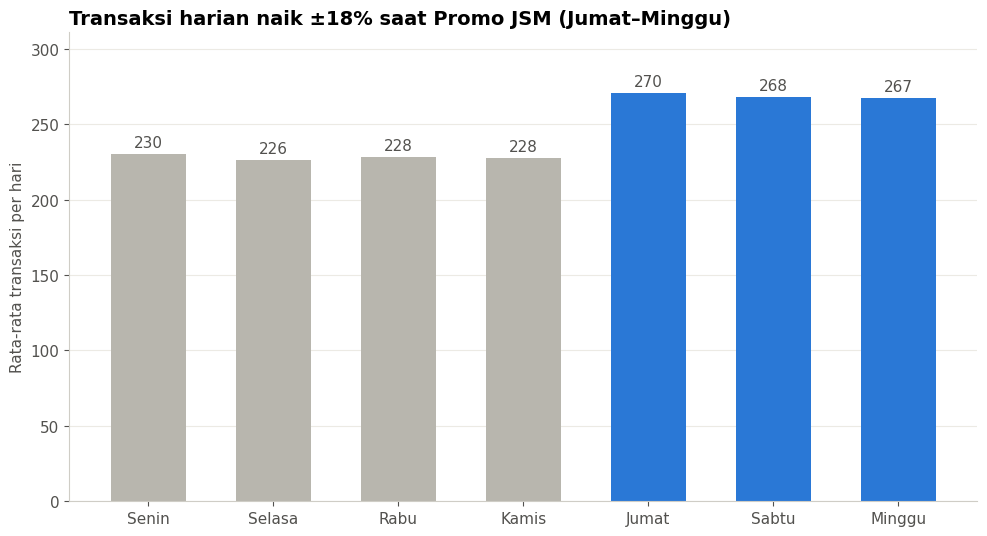

In [18]:
urutan = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
label  = ['Senin','Selasa','Rabu','Kamis','Jumat','Sabtu','Minggu']
nilai  = per_hari.reindex(urutan).values

fig, ax = plt.subplots()
bars = ax.bar(label, nilai, color=[ABU]*4 + [BIRU]*3, width=0.6)
ax.bar_label(bars, fmt='%.0f', color=TEKS, padding=3)
ax.set_title('Transaksi harian naik ±18% saat Promo JSM (Jumat–Minggu)')
ax.set_ylabel('Rata-rata transaksi per hari')
ax.set_ylim(0, nilai.max() * 1.15)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
simpan('01_transaksi_per_hari')

> ✍️ **Insight:** Transaksi harian stabil di ±226–230 pada Senin–Kamis, lalu naik ke ±267–270 pada Jumat–Minggu (**+18%**). Promo JSM berhasil menarik kunjungan, jadi rekomendasinya bukan menghapus promo.

### 10.2 Sebaran qty SKU promo: hari biasa vs JSM
Boxplot dipakai untuk membandingkan **sebaran** dua kelompok. Titik ekstrem disembunyikan (`showfliers=False`) supaya kotak tetap terbaca.

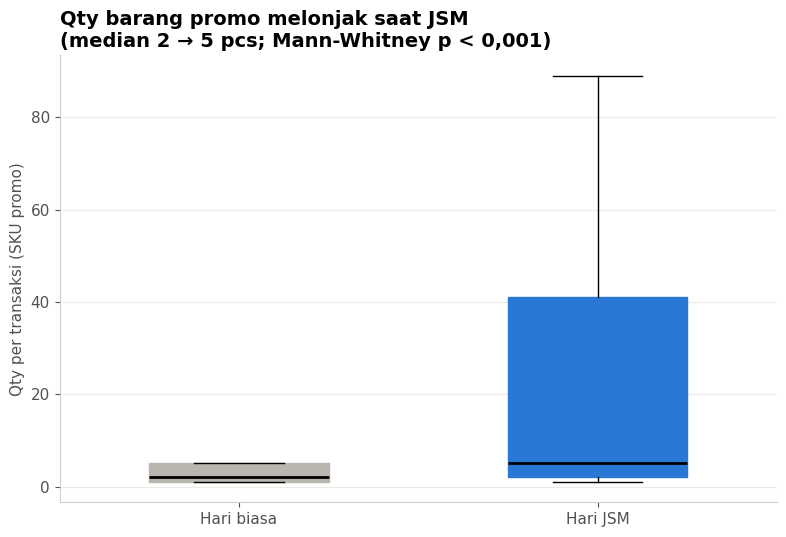

In [19]:
fig, ax = plt.subplots(figsize=(8, 5.5))
bp = ax.boxplot([qty_biasa, qty_jsm], showfliers=False, patch_artist=True,
                widths=0.5, medianprops=dict(color='black', linewidth=2))
for kotak, warna in zip(bp['boxes'], [ABU, BIRU]):
    kotak.set_facecolor(warna); kotak.set_edgecolor(warna)
ax.set_xticks([1, 2]); ax.set_xticklabels(['Hari biasa', 'Hari JSM'])
ax.set_title('Qty barang promo melonjak saat JSM\n(median 2 → 5 pcs; Mann-Whitney p < 0,001)')
ax.set_ylabel('Qty per transaksi (SKU promo)')
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
simpan('02_boxplot_qty_promo')

> ✍️ **Insight:** Sebaran qty SKU promo saat JSM jauh lebih lebar dan lebih tinggi (median 2 → 5 pcs; kotak JSM hingga ±40 pcs), dan perbedaannya signifikan secara statistik (Mann-Whitney p < 0,001).

### 10.3 Konsentrasi diskon JSM
Kurva kumulatif dipakai untuk melihat seberapa timpang pembagian diskon. Garis putus-putus = kondisi kalau diskon terbagi merata.

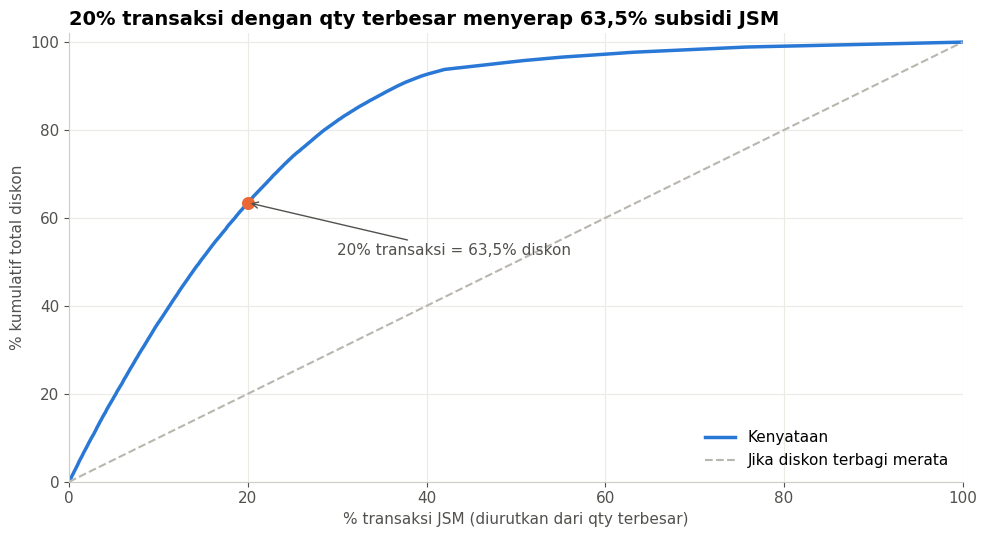

In [20]:
x = np.arange(1, len(d) + 1) / len(d) * 100
y = d['porsi_diskon_kumulatif'].values * 100
y20 = y[int(len(d) * 0.2) - 1]
y20_txt = f'{y20:.1f}'.replace('.', ',')

fig, ax = plt.subplots()
ax.plot(x, y, color=BIRU, linewidth=2.5, label='Kenyataan')
ax.plot([0, 100], [0, 100], '--', color=ABU, linewidth=1.5, label='Jika diskon terbagi merata')
ax.scatter([20], [y20], color=ORANYE, s=70, zorder=3)
ax.annotate(f'20% transaksi = {y20_txt}% diskon', xy=(20, y20), xytext=(30, y20 - 12),
            arrowprops=dict(arrowstyle='->', color=TEKS), color=TEKS, fontsize=11)
ax.set_title(f'20% transaksi dengan qty terbesar menyerap {y20_txt}% subsidi JSM')
ax.set_xlabel('% transaksi JSM (diurutkan dari qty terbesar)')
ax.set_ylabel('% kumulatif total diskon')
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.legend(frameon=False, loc='lower right')
ax.grid(True, color=GRID); ax.set_axisbelow(True)
simpan('03_konsentrasi_diskon')

> ✍️ **Insight:** Kurva kenyataan jauh di atas garis "merata". **20% transaksi terbesar menyerap 63,5% diskon**, dan ±40% transaksi teratas sudah menyerap >90% diskon. Subsidi promo terkonsentrasi pada pembelian bervolume besar.

### 10.4 Median qty SKU promo per tipe gerai
Grouped bar chart dipakai untuk membandingkan dua kondisi (hari biasa vs JSM) di setiap tipe gerai.

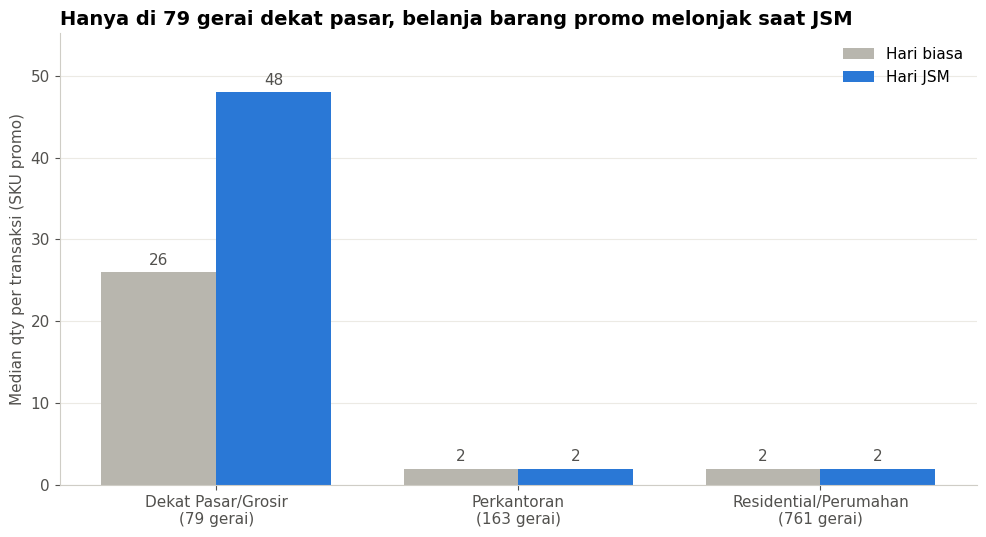

In [21]:
med = p2.groupby(['store_type', 'is_jsm'])['qty'].median().unstack()
med = med.loc[['Dekat Pasar/Grosir', 'Perkantoran', 'Residential/Perumahan']]
jml = stores['store_type'].value_counts()
label = [f'{s}\n({jml[s]} gerai)' for s in med.index]

xpos, w = np.arange(len(med)), 0.38
fig, ax = plt.subplots()
b1 = ax.bar(xpos - w/2, med[False], w, color=ABU,  label='Hari biasa')
b2 = ax.bar(xpos + w/2, med[True],  w, color=BIRU, label='Hari JSM')
ax.bar_label(b1, fmt='%.0f', color=TEKS, padding=3)
ax.bar_label(b2, fmt='%.0f', color=TEKS, padding=3)
ax.set_xticks(xpos); ax.set_xticklabels(label)
ax.set_title('Hanya di 79 gerai dekat pasar, belanja barang promo melonjak saat JSM')
ax.set_ylabel('Median qty per transaksi (SKU promo)')
ax.legend(frameon=False)
ax.set_ylim(0, med.values.max() * 1.15)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
simpan('04_qty_per_tipe_gerai')

> ✍️ **Insight:** Hanya gerai **Dekat Pasar/Grosir (79 gerai)** yang qty-nya berubah saat JSM (median **26 → 48 pcs**). Gerai perkantoran dan perumahan tetap **2 pcs**. Masalahnya **terlokalisasi di gerai dekat pasar**, sehingga kebijakan bisa dibuat tepat sasaran.

### 10.5 Simulasi batas qty: penghematan vs dampak ke pelanggan biasa
Grafik trade-off: sumbu Y = rupiah yang dihemat, sumbu X = persentase transaksi pelanggan rumah tangga yang ikut terkena batas.

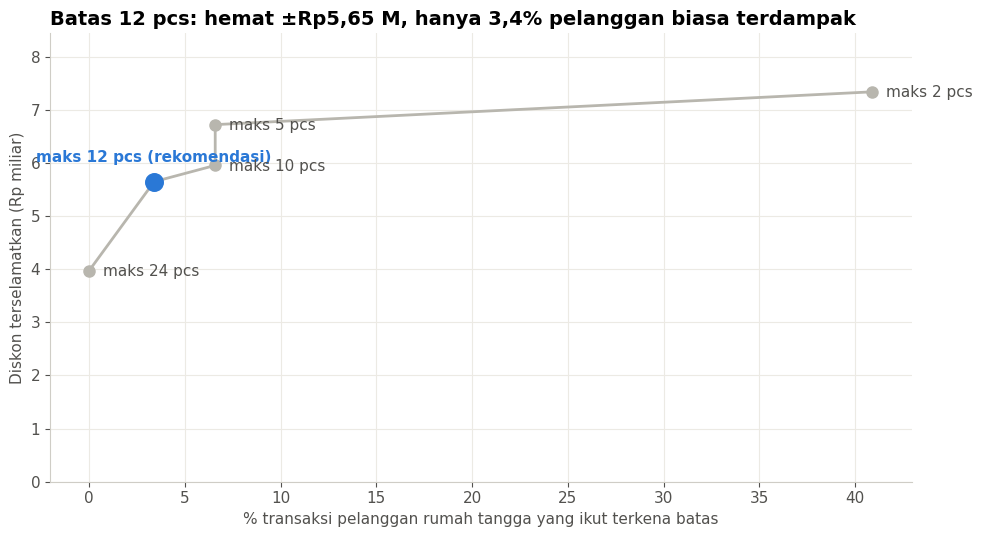

In [22]:
s = sim.sort_values('trx_kena_gerai_non_pasar')
xk = s['trx_kena_gerai_non_pasar'] * 100
yk = s['diskon_terselamatkan'] / 1e9

fig, ax = plt.subplots()
ax.plot(xk, yk, color=ABU, linewidth=2, marker='o', markersize=8, zorder=2)
pilih = s['batas_qty'] == 12
ax.scatter(xk[pilih], yk[pilih], color=BIRU, s=160, zorder=3)
for cap, xi, yi in zip(s['batas_qty'], xk, yk):
    if cap == 12:
        ax.annotate('maks 12 pcs (rekomendasi)', (xi, yi), xytext=(0, 14),
                    textcoords='offset points', ha='center', color=BIRU, fontweight='bold')
    else:
        ax.annotate(f'maks {cap} pcs', (xi, yi), xytext=(10, -4),
                    textcoords='offset points', color=TEKS)
ax.set_title('Batas 12 pcs: hemat ±Rp5,65 M, hanya 3,4% pelanggan biasa terdampak')
ax.set_xlabel('% transaksi pelanggan rumah tangga yang ikut terkena batas')
ax.set_ylabel('Diskon terselamatkan (Rp miliar)')
ax.set_ylim(0, yk.max() * 1.15)
ax.grid(True, color=GRID); ax.set_axisbelow(True)
simpan('05_simulasi_batas_qty')

> ✍️ **Insight:** Makin ketat batasnya, makin besar penghematan, tetapi makin banyak pelanggan biasa yang dirugikan. Batas **12 pcs** berada di titik "tinggi tapi tetap di kiri": hemat ±Rp5,65 M dengan hanya 3,4% pelanggan biasa terdampak. Batas 2 pcs hanya menambah ±Rp1,7 M penghematan, tetapi mengorbankan ±41% pelanggan.

## 11. Kesimpulan

1. **Dugaan kebocoran margin terbukti, dengan koreksi.** Promo JSM memang memicu pembelian borongan (qty SKU promo naik ±2,7×, signifikan p < 0,001). Namun pelakunya **bukan segelintir pembeli** (11.395 member), melainkan **terpusat di 79 gerai Dekat Pasar/Grosir**. Di gerai lain, promo tidak mengubah perilaku belanja.
2. **Promo JSM tetap efektif menarik kunjungan:** rata-rata transaksi harian naik **±18%** di hari JSM.
3. **Tujuan #1 (dampak finansial):** dari total diskon JSM **±Rp7,98 M** (Jan 2021–Agu 2025), **±Rp3,97 M (49,8%)** jatuh ke unit di atas batas wajar rumah tangga, atau **±Rp0,85 M per tahun**. Angka ini estimasi konservatif karena memakai batas longgar (24 pcs).
4. **Tujuan #2 (kebijakan):** dari 3 skenario yang disimulasikan, **Skenario 2 (batas 12 pcs per SKU promo per transaksi)** adalah yang paling seimbang: menyelamatkan hingga **±Rp1,2 M/tahun** dengan dampak hanya **3,4%** ke transaksi pelanggan rumah tangga. Skenario 1 (2 pcs, seperti aturan minyak goreng 2022) terlalu ketat karena 41% pelanggan biasa ikut terkena. Skenario 3 (24 pcs) tidak mengganggu pelanggan biasa, tetapi hanya menutup ±Rp0,85 M/tahun.

## 12. Rekomendasi

| # | Rekomendasi | Pelaksana | Dasar data | Dampak | Risiko / pertimbangan |
|---|---|---|---|---|---|
| 1 | Terapkan **batas maks 12 pcs per SKU promo per transaksi** saat JSM, mulai dari **79 gerai Dekat Pasar/Grosir** | Tim Promo + Tim IT/POS | Kebocoran 100% di gerai dekat pasar; batas 12 = p95 pelanggan perumahan | Hemat hingga **±Rp1,2 M/tahun** | Pembeli bisa memecah transaksi; sebagian pedagang bisa pindah ke toko lain |
| 2 | Tambahkan **batas akumulasi per `member_id` per periode JSM** untuk mencegah pemecahan transaksi | Tim CRM/Member + Tim IT/POS | 73% kebocoran berasal dari transaksi ber-member | Menutup celah split transaksi | Non-member (27% kebocoran) tidak terlacak, jadi tetap mengandalkan batas per transaksi |
| 3 | Sediakan **skema harga grosir terpisah** (tanpa subsidi JSM) untuk pedagang di gerai dekat pasar | Tim Komersial / Area Manager | Median qty gerai dekat pasar sudah 26 pcs di hari biasa → segmen pedagang nyata | Mempertahankan penjualan ke pedagang tanpa membakar subsidi promo | Perlu kajian harga dan margin grosir |
| 4 | **Pantau dan evaluasi** dalam 1 kuartal: median qty SKU promo saat JSM di gerai dekat pasar, total diskon JSM, dan traffic harian. Tambahkan **validasi input di POS** (blok qty ≤ 0 / > 500, cek tanggal transaksi) | Tim Data/BI + Tim IT/POS | Ditemukan 2.976 qty mustahil dan 8.657 transaksi bertanggal sebelum gerai buka | Memastikan kebijakan berjalan dan data ke depan lebih bersih | Butuh dashboard dan pemantauan rutin |

**Dampak bisnis (estimasi per tahun):**

| Skenario | Diskon JSM | Diskon yang bocor | Traffic JSM |
|---|---|---|---|
| Sebelum (kondisi sekarang) | ±Rp1,71 M | ≥ ±Rp0,85 M | +18% |
| Sesudah (batas 12 pcs) | berkurang hingga ±Rp1,2 M (menjadi ±Rp0,5 M) | sebagian besar tertutup | diharapkan tetap (96,6% transaksi pelanggan biasa tidak terdampak) |

## 13. Keterbatasan Data

- **Harga produk tidak konsisten:** satu nama produk memiliki harga Rp3.200–Rp44.800, sehingga analisis tidak dapat dilakukan per nama produk. Analisis dibatasi pada level SKU, kategori, dan status promo.
- **Tidak ada data harga pokok (HPP):** "kebocoran" diukur dari **nilai diskon**, bukan margin sebenarnya.
- **Asumsi batas wajar rumah tangga:** batas 24 pcs (p90 hari biasa) dan 12 pcs (p95 gerai perumahan) adalah pendekatan, bukan definisi resmi kebutuhan rumah tangga.
- **"Diskon terselamatkan" adalah angka maksimal:** belum memperhitungkan pembeli yang pindah ke toko lain atau memecah transaksi.
- **Satu `receipt_id` = satu SKU:** tidak ada data isi keranjang, sehingga perilaku belanja per kunjungan tidak bisa dianalisis.
- **±34% transaksi tanpa `member_id`:** pembeli non-member tidak bisa dilacak per orang.
- **Pola data sangat rapi** (misalnya qty gerai non-pasar identik di semua kondisi), yang mengindikasikan data simulasi. Temuan perlu divalidasi dengan data operasional riil sebelum kebijakan diterapkan.

In [23]:
# # ===== Siapkan data untuk dashboard Looker Studio =====
# from google.colab import auth
# auth.authenticate_user()
# import gspread
# from google.auth import default
# creds, _ = default()
# gc = gspread.authorize(creds)

# nama_hari = {0:'1 Senin', 1:'2 Selasa', 2:'3 Rabu', 3:'4 Kamis',
#              4:'5 Jumat', 5:'6 Sabtu', 6:'7 Minggu'}

# a = t.merge(stores[['store_id', 'store_type', 'city']], on='store_id')
# a['tanggal']      = a['trx_time'].dt.strftime('%Y-%m-%d')
# a['hari']         = a['trx_time'].dt.dayofweek.map(nama_hari)
# a['jenis_hari']   = np.where(a['is_jsm'], 'JSM (Jumat-Minggu)', 'Hari biasa')
# a['status_promo'] = np.where(a['is_jsm_promo'] == 1, 'SKU promo', 'SKU non-promo')

# # kebocoran per transaksi (logika sama dengan bagian 9.3)
# a['diskon_bocor'] = 0.0
# m = (a['is_jsm_promo'] == 1) & (a['is_jsm'])
# lebih = (a.loc[m, 'qty'] - a.loc[m, 'category'].map(batas)).clip(lower=0)
# a.loc[m, 'diskon_bocor'] = lebih * a.loc[m, 'discount_amount'] / a.loc[m, 'qty']

# # Tab 1: harian
# harian = (a.groupby(['tanggal', 'hari', 'jenis_hari', 'store_type', 'category', 'status_promo'])
#            .agg(jumlah_transaksi=('receipt_id', 'count'),
#                 total_qty=('qty', 'sum'),
#                 total_penjualan=('total_price', 'sum'),
#                 total_diskon=('discount_amount', 'sum'),
#                 diskon_bocor=('diskon_bocor', 'sum'))
#            .reset_index())

# # Tab 2: gerai
# gerai = (a.groupby(['store_id', 'store_type', 'city'])
#           .agg(jumlah_transaksi=('receipt_id', 'count'),
#                total_diskon=('discount_amount', 'sum'),
#                diskon_bocor=('diskon_bocor', 'sum'))
#           .reset_index())

# # Tab 3: simulasi
# simulasi = sim.copy()
# simulasi['diskon_terselamatkan_miliar'] = simulasi['diskon_terselamatkan'] / 1e9
# for c in ['porsi_diskon', 'trx_kena_semua_gerai', 'trx_kena_gerai_non_pasar']:
#     simulasi[c] = simulasi[c] * 100
# simulasi['batas_qty'] = simulasi['batas_qty'].astype(str) + ' pcs'

# # Kirim ke Google Sheet baru
# sh = gc.create('Capstone3_Alfamart_Looker')
# for i, (nama, df) in enumerate([('harian', harian), ('gerai', gerai), ('simulasi', simulasi)]):
#     ws = sh.sheet1 if i == 0 else sh.add_worksheet(nama, rows=1, cols=1)
#     if i == 0: ws.update_title(nama)
#     df = df.round(2)
#     ws.update([df.columns.tolist()] + df.astype(object).values.tolist())
#     print(f"{nama}: {len(df):,} baris")

# print("\nSelesai! Buka:", sh.url)

harian: 33,463 baris


KeyboardInterrupt: 